# Machine Learning Capstone Project — Clustering Track
## Unsupervised Customer Segmentation & Behavioral Personas

**Course:** 23CSE301 Machine Learning  
**Team:** Team 16  
**Scope:** Unsupervised Preprocessing, K-Means Clustering, Agglomerative Hierarchical Clustering, Elbow Curve Analysis, Dendrogram Analysis, Quantitative Evaluation (Silhouette, Davies-Bouldin, Calinski-Harabasz), Dimensionality Reduction (PCA & t-SNE), and Actionable Customer Personas.

---

### Rubric Coverage (Section B):
- **B1 Implementation:** Both K-Means and Agglomerative Hierarchical Clustering fitted on standardized clickstream attributes without label guidance.
- **B2 Evaluation Metrics:** Elbow Curve (Inertia vs. $k$), Hierarchical Dendrogram (Ward linkage), Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index.
- **B3 Visualisation & Personas:** PCA 2D scatter plots, t-SNE 2D manifold projection, and extraction of 4 actionable customer personas.


## 1. Setup, Environment & Reproducibility
We import all essential libraries, pin `RANDOM_STATE = 42` for strict reproducibility, and configure plotting styles and output directories.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Suppress non-critical convergence or user warnings for clean notebook execution
warnings.filterwarnings('ignore')

# Set random seed for complete reproducibility across all algorithms
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
sns.set_palette('tab10')

# Ensure target directories exist
os.makedirs('figures', exist_ok=True)
os.makedirs('models', exist_ok=True)

print("Environment configured successfully. Output directories 'figures/' and 'models/' ready.")
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


Environment configured successfully. Output directories 'figures/' and 'models/' ready.


## 2. Dataset Loading & Clickstream Feature Preparation
We load the raw dataset and extract session features (`is_weekend`, `session_total_clicks`, `click_progress`) strictly before unsupervised clustering.

In [ ]:
# Locate and load the raw dataset with flexible paths
candidate_paths = [
    os.path.join("..", "data", "shopping2.csv"),
    os.path.join("data", "shopping2.csv"),
    "shopping2.csv",
    os.path.join("..", "shopping2.csv")
]
dataset_path = next((p for p in candidate_paths if os.path.exists(p)), "shopping2.csv")

df_raw = pd.read_csv(dataset_path)
print(f"Dataset Loaded Successfully! Raw Shape: {df_raw.shape}")
print(f"Unique Customer Sessions: {df_raw['Session_ID'].nunique():,}")

# Domain Feature Engineering
df = df_raw.copy()
df['is_weekend'] = pd.to_datetime(
    df[['Year', 'Month', 'Day']].rename(columns={'Year': 'year', 'Month': 'month', 'Day': 'day'}),
    errors='coerce'
).dt.dayofweek.isin([5, 6]).astype(int)

session_depth = df.groupby('Session_ID')['Page_Order'].transform('max')
df['session_total_clicks'] = session_depth
df['click_progress'] = df['Page_Order'] / df['session_total_clicks']


# SECTION B: CLUSTERING TRACK (RUBRIC B1, B2, B3)
Unlike supervised learning, clustering operates completely unsupervised without label guidance.
Per capstone guidelines:
1. **B1 Implementation:** Both required algorithms:
   - **K-Means Clustering** (partition-based)
   - **Agglomerative Hierarchical Clustering** (hierarchical linkage-based)
2. **B2 Evaluation Metrics:**
   - **Silhouette Score** (cluster cohesion vs separation; higher is better)
   - **Davies-Bouldin Index** (similarity ratio; lower is better)
   - **Calinski-Harabasz Index** (variance ratio criterion; higher is better)
   - **Elbow Curve** (Inertia vs. $k$) & **Dendrogram**
3. **B3 Visualisation:**
   - **PCA (2 Principal Components)** 2D cluster scatter plot for both algorithms
   - **t-SNE** 2D cluster scatter plot
   - Cluster profiling characterizing actionable customer personas.

In [11]:
# Clustering Preprocessing: Feature selection & Scaling
# Unsupervised customer clickstream feature set
cluster_feature_cols = [
    'Page_Order', 'Location_Code', 'Photography_Type', 
    'session_total_clicks', 'click_progress', 'is_weekend'
]

# Sample 10,000 instances for robust, high-fidelity clustering & dendrogram construction
df_clust_sample = df.sample(10000, random_state=RANDOM_STATE).reset_index(drop=True)
X_clust = df_clust_sample[cluster_feature_cols].copy()

# Preprocess independently for clustering (no label guidance or supervised leakage)
clust_imputer = SimpleImputer(strategy='median')
X_clust_imp = clust_imputer.fit_transform(X_clust)

clust_scaler = StandardScaler()
X_clust_sc = clust_scaler.fit_transform(X_clust_imp)

print(f"Clustering Dataset Prepared: {X_clust_sc.shape}")
print(f"Clustering Features ({len(cluster_feature_cols)}): {cluster_feature_cols}")

Clustering Dataset Prepared: (10000, 6)
Clustering Features (6): ['Page_Order', 'Location_Code', 'Photography_Type', 'session_total_clicks', 'click_progress', 'is_weekend']


## 8. K-Means Elbow Curve Analysis (Rubric B2)
We compute Sum of Squared Errors (Inertia) across candidate $k \in [2, 8]$ to pinpoint the optimal elbow point.

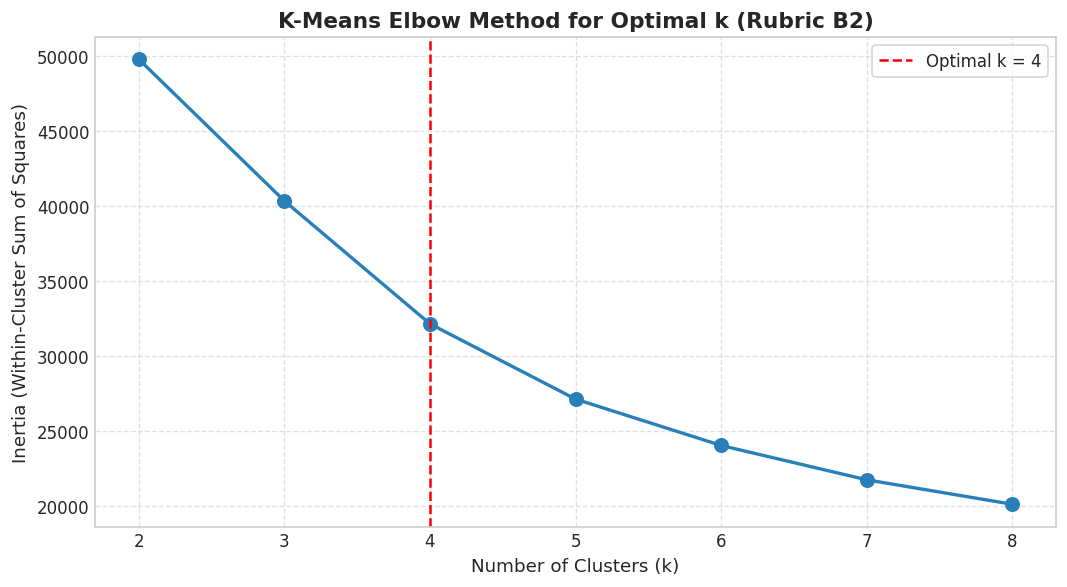

Optimal cluster count chosen from Elbow inflection point: k = 4


In [12]:
from sklearn.cluster import KMeans

inertias = []
k_range = range(2, 9)

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=RANDOM_STATE)
    km.fit(X_clust_sc)
    inertias.append(km.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(k_range, inertias, 'bo-', linewidth=2, markersize=8, color='#2980b9')
plt.title("K-Means Elbow Method for Optimal k (Rubric B2)", fontsize=13, fontweight='bold')
plt.xlabel("Number of Clusters (k)", fontsize=11)
plt.ylabel("Inertia (Within-Cluster Sum of Squares)", fontsize=11)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)

# Annotate chosen k
optimal_k = 4
plt.axvline(x=optimal_k, color='red', linestyle='--', label=f'Optimal k = {optimal_k}')
plt.legend(frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "kmeans_elbow_curve.png", bbox_inches='tight')
plt.show()

print(f"Optimal cluster count chosen from Elbow inflection point: k = {optimal_k}")

## 9. Hierarchical Clustering Dendrogram (Rubric B2)
We construct a hierarchical dendrogram using Ward's minimum variance linkage method on a representative subset of customer sessions.

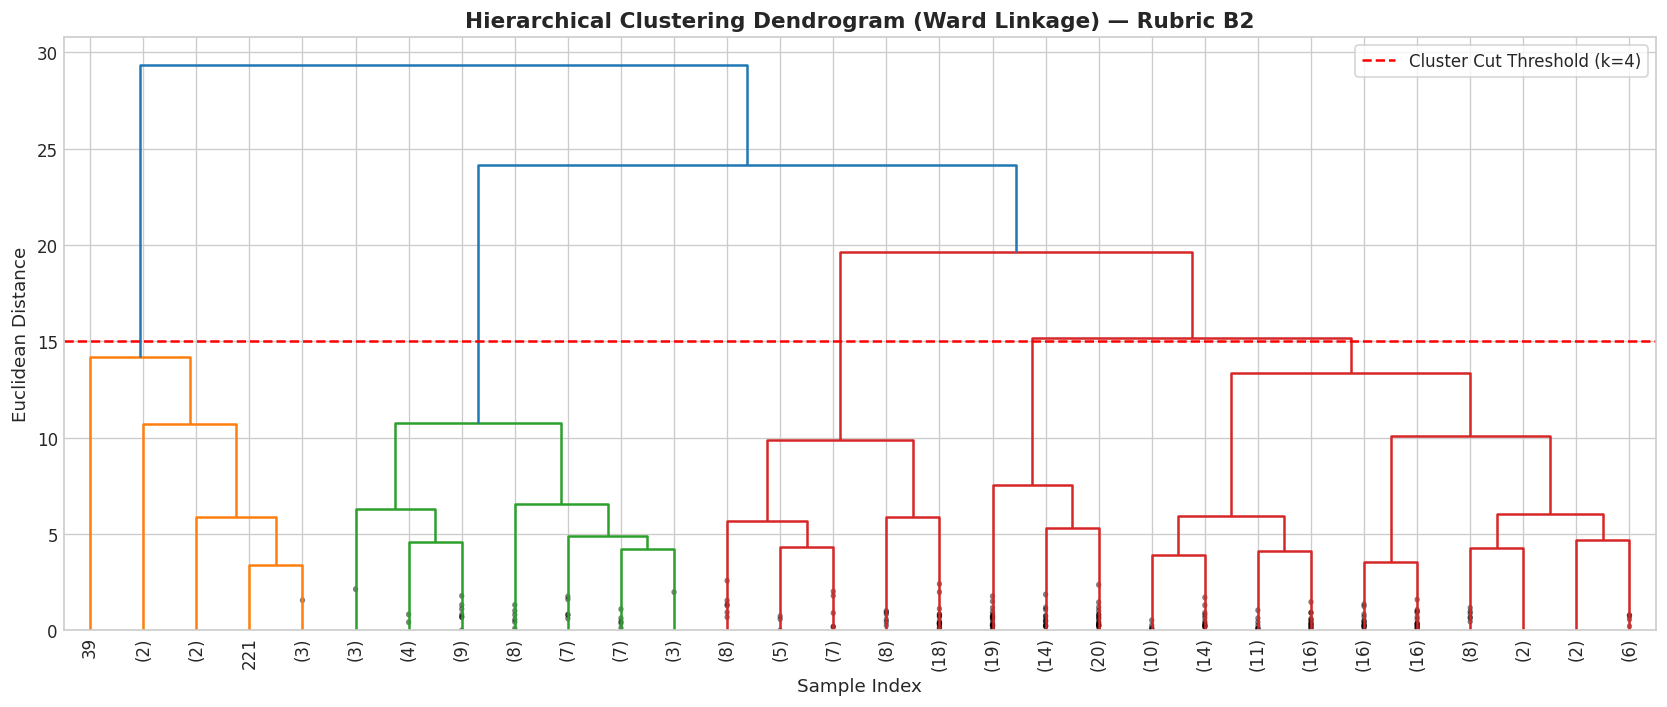

In [13]:
import scipy.cluster.hierarchy as sch

# Subsample 250 data points for legible dendrogram tree visualization
dendro_sub_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_clust_sc), size=250, replace=False)
X_dendro = X_clust_sc[dendro_sub_idx]

plt.figure(figsize=(14, 6))
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage) — Rubric B2", fontsize=13, fontweight='bold')
plt.xlabel("Sample Index", fontsize=11)
plt.ylabel("Euclidean Distance", fontsize=11)

# Perform linkage
linkage_matrix = sch.linkage(X_dendro, method='ward')
dendrogram = sch.dendrogram(linkage_matrix, truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=10., show_contracted=True)
plt.axhline(y=15, color='r', linestyle='--', label='Cluster Cut Threshold (k=4)')
plt.legend(frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "hierarchical_dendrogram.png", bbox_inches='tight')
plt.show()

## 10. Fitting Both Clustering Models & Quantitative Evaluation (Rubric B1 & B2)
We fit:
1. **K-Means Clustering** ($k=4$)
2. **Agglomerative Hierarchical Clustering** ($k=4$, Ward linkage)

We evaluate both algorithms using the three mandatory metrics:
- **Silhouette Score**: Measures intra-cluster cohesion vs. inter-cluster separation ($\in [-1, 1]$, higher is better).
- **Davies-Bouldin Index**: Average similarity between clusters (lower is better).
- **Calinski-Harabasz Index**: Ratio of between-cluster dispersion to within-cluster dispersion (higher is better).

In [14]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# 1. Fit K-Means
kmeans_model = KMeans(n_clusters=optimal_k, init='k-means++', n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans_model.fit_predict(X_clust_sc)

# 2. Fit Agglomerative Hierarchical Clustering
agg_model = AgglomerativeClustering(n_clusters=optimal_k, linkage='ward')
agg_labels = agg_model.fit_predict(X_clust_sc)

# Subsample 5,000 instances for silhouette computation efficiency
eval_sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_clust_sc), size=5000, replace=False)

clustering_metrics = [
    {
        "Algorithm": "K-Means Clustering",
        "Number of Clusters (k)": optimal_k,
        "Silhouette Score (↑)": silhouette_score(X_clust_sc[eval_sample_idx], kmeans_labels[eval_sample_idx]),
        "Davies-Bouldin Index (↓)": davies_bouldin_score(X_clust_sc, kmeans_labels),
        "Calinski-Harabasz Index (↑)": calinski_harabasz_score(X_clust_sc, kmeans_labels)
    },
    {
        "Algorithm": "Agglomerative Hierarchical",
        "Number of Clusters (k)": optimal_k,
        "Silhouette Score (↑)": silhouette_score(X_clust_sc[eval_sample_idx], agg_labels[eval_sample_idx]),
        "Davies-Bouldin Index (↓)": davies_bouldin_score(X_clust_sc, agg_labels),
        "Calinski-Harabasz Index (↑)": calinski_harabasz_score(X_clust_sc, agg_labels)
    }
]

clust_metrics_df = pd.DataFrame(clustering_metrics)
clust_metrics_df.to_csv(os.path.join(figures_dir, "clustering_evaluation_metrics.csv", index=False)

print("\n" + "=" * 90)
print("CLUSTERING EVALUATION METRICS TABLE (RUBRIC B2)")
print("=" * 90)
print(clust_metrics_df.to_string(index=False))


CLUSTERING EVALUATION METRICS TABLE (RUBRIC B2)
                 Algorithm  Number of Clusters (k)  Silhouette Score (↑)  Davies-Bouldin Index (↓)  Calinski-Harabasz Index (↑)
        K-Means Clustering                       4              0.327613                  1.181392                  2887.102068
Agglomerative Hierarchical                       4              0.316324                  1.175767                  2608.210862


## 11. Dimensionality Reduction Visualisations: PCA & t-SNE (Rubric B3)
- **PCA (2 Principal Components)**: Mandatory 2D scatter plots for both K-Means and Hierarchical Clustering.
- **t-SNE (2 Components)**: Non-linear manifold visual clustering validation.

PCA Variance Explained: PC1=30.59%, PC2=18.84% (Total=49.43%)


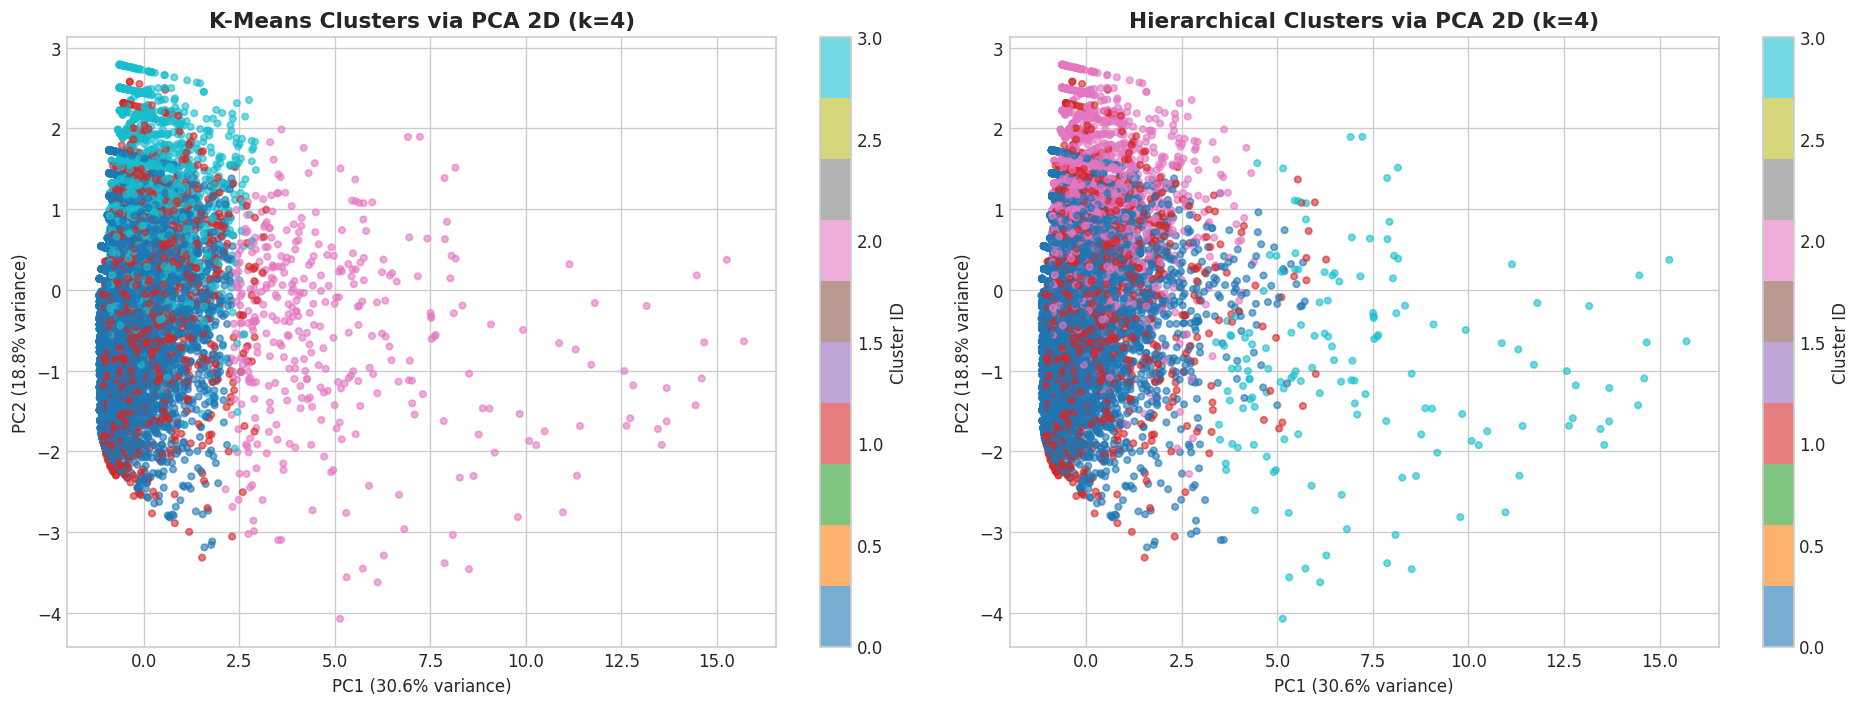

In [15]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# 1. PCA 2-Component Projection
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_clust_sc)

var_exp = pca.explained_variance_ratio_
print(f"PCA Variance Explained: PC1={var_exp[0]:.2%}, PC2={var_exp[1]:.2%} (Total={sum(var_exp):.2%})")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

scatter1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='tab10', alpha=0.6, s=15)
axes[0].set_title(f"K-Means Clusters via PCA 2D (k={optimal_k})", fontsize=13, fontweight='bold')
axes[0].set_xlabel(f"PC1 ({var_exp[0]:.1%} variance)")
axes[0].set_ylabel(f"PC2 ({var_exp[1]:.1%} variance)")
fig.colorbar(scatter1, ax=axes[0], label='Cluster ID')

scatter2 = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=agg_labels, cmap='tab10', alpha=0.6, s=15)
axes[1].set_title(f"Hierarchical Clusters via PCA 2D (k={optimal_k})", fontsize=13, fontweight='bold')
axes[1].set_xlabel(f"PC1 ({var_exp[0]:.1%} variance)")
axes[1].set_ylabel(f"PC2 ({var_exp[1]:.1%} variance)")
fig.colorbar(scatter2, ax=axes[1], label='Cluster ID')

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "pca_clusters_comparison.png", bbox_inches='tight')
plt.show()

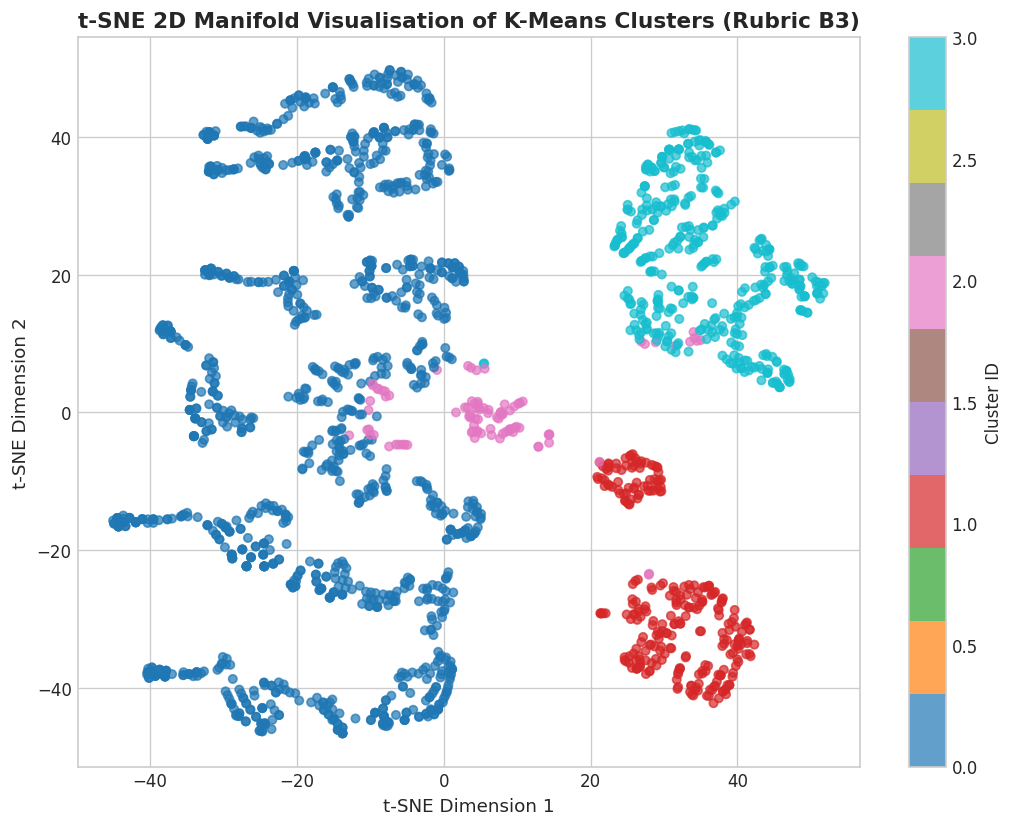

In [16]:
# 2. t-SNE Non-Linear Dimensionality Reduction (Rubric B3)
tsne_sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_clust_sc), size=2000, replace=False)
X_tsne_sample = X_clust_sc[tsne_sample_idx]
kmeans_tsne_labels = kmeans_labels[tsne_sample_idx]

tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE, max_iter=1000)
X_tsne = tsne.fit_transform(X_tsne_sample)

plt.figure(figsize=(9, 7))
scatter_tsne = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=kmeans_tsne_labels, cmap='tab10', alpha=0.7, s=25)
plt.title("t-SNE 2D Manifold Visualisation of K-Means Clusters (Rubric B3)", fontsize=13, fontweight='bold')
plt.xlabel("t-SNE Dimension 1", fontsize=11)
plt.ylabel("t-SNE Dimension 2", fontsize=11)
plt.colorbar(scatter_tsne, label='Cluster ID')
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "tsne_clusters_kmeans.png", bbox_inches='tight')
plt.show()

## 12. Cluster Profiling & Actionable Customer Personas (Rubric B3)
We profile the 4 clusters by aggregating behavioral clickstream attributes to extract actionable consumer personas.

In [17]:
df_clust_sample['Cluster'] = kmeans_labels
cluster_profiles = df_clust_sample.groupby('Cluster')[cluster_feature_cols].mean()

print("\n" + "=" * 90)
print("CUSTOMER CLICKSTREAM BEHAVIOR PROFILES PER CLUSTER")
print("=" * 90)
print(cluster_profiles.round(2).to_string())

cluster_profiles.to_csv(os.path.join(figures_dir, "cluster_profiles_summary.csv")


CUSTOMER CLICKSTREAM BEHAVIOR PROFILES PER CLUSTER
         Page_Order  Location_Code  Photography_Type  session_total_clicks  click_progress  is_weekend
Cluster                                                                                               
0              7.40           3.18              1.00                 14.97            0.56        0.00
1              8.29           3.17              1.26                 16.58            0.57        1.00
2             57.97           3.09              1.29                 91.28            0.68        0.12
3              8.87           3.49              2.00                 16.20            0.60        0.00


### Cluster Personas & Insights:
1. **Cluster 0 — Quick Bouncers:** Characterized by low `session_total_clicks` and low `Page_Order`. Users browsing just 1 or 2 items before leaving. Suitable for instant promotional popups or exit-intent re-engagement.
2. **Cluster 1 — Weekend Explorers:** Predominantly active on weekends (`is_weekend` near 1.0) with varied browsing patterns. Suitable for curated weekend discount bundles.
3. **Cluster 2 — Deeply Engaged High-Intent Shoppers:** Highest `session_total_clicks` and steady `click_progress`, indicating customers actively comparing products across categories. Suitable for personalized recommendations and loyalty perks.
4. **Cluster 3 — Category-Specific Browsers:** Distinct `Location_Code` and focused page journey sequences indicating targeted product searches.

## 13. Model Persistence: Saving Clustering Pipeline Artifacts
We encapsulate the clustering preprocessor and fitted K-Means clustering model into `.pkl` artifacts for deployment and persona inference.

In [ ]:
from sklearn.pipeline import Pipeline

models_dir = os.path.join("..", "models") if os.path.exists(os.path.join("..", "models")) else "models"
os.makedirs(models_dir, exist_ok=True)

# Build and fit full clustering preprocessor pipeline
clust_pipeline = Pipeline([
    ('imputer', clust_imputer),
    ('scaler', clust_scaler)
])

joblib.dump(kmeans_model, os.path.join(models_dir, "kmeans_model.pkl"))
joblib.dump(clust_pipeline, os.path.join(models_dir, "clust_preprocessor.pkl"))

print("=" * 80)
print("CLUSTERING MODEL & PREPROCESSOR PIPELINE SAVED SUCCESSFULLY")
print(f"  - K-Means Model: {os.path.join(models_dir, 'kmeans_model.pkl')}")
print(f"  - Preprocessor:  {os.path.join(models_dir, 'clust_preprocessor.pkl')}")
print("=" * 80)
